# AST epoch 연장 실험

기존 6 epoch의 가중치·AdamW·난수 상태를 이어받아 최대 30 epoch까지 학습합니다. 학습률과 학습 633개·개발 평가 122개는 그대로 유지합니다. 개발 proxy가 5 epoch 연속 개선되지 않으면 중단하고 최적 checkpoint를 복원합니다. 기존 평가 274개는 후속 비교용이며 새로운 독립 검증이 아닙니다. 이번 A100 할당은 최대 30분입니다.

In [1]:
import time, json, shutil, subprocess, sys, zipfile, hashlib, threading, traceback, os
from pathlib import Path
from google.colab import drive, runtime
SESSION_START = time.time()
DEADLINE = SESSION_START + 1680
drive.mount('/content/drive')
DRIVE = Path('/content/drive/MyDrive/DACON_236749')
PRIMARY = DRIVE / 'runs_v2/20260912_174330'
RUN = DRIVE / 'runs_v2' / ('epoch_extension_' + time.strftime('%Y%m%d_%H%M%S',time.gmtime(SESSION_START)))
RUN.mkdir()
WORK = Path('/content/dacon_epoch_extension')
WORK.mkdir(exist_ok=True)
watchdog = threading.Timer(max(1,DEADLINE-time.time()),runtime.unassign)
watchdog.daemon = True
watchdog.start()
(RUN / 'budget.json').write_text(json.dumps({'start_unix':SESSION_START,'deadline':DEADLINE,'allocation_limit_seconds':1800}))
for source in (PRIMARY / 'code').iterdir():
    if source.is_file():
        shutil.copy2(source,WORK / source.name)
print('RESULTS_DIRECTORY',RUN,flush=True)

Mounted at /content/drive
RESULTS_DIRECTORY /content/drive/MyDrive/DACON_236749/runs_v2/epoch_extension_20260913_013624


In [2]:
%%writefile /content/dacon_epoch_extension/train_v2.py
"""Bounded AST training on development data only."""

from __future__ import annotations

import argparse
import csv
import hashlib
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import torch

from graph_features import atomic_json, digest
from graph_scoring import LABEL_COLUMNS, PREDICTION_COLUMNS, official_metrics
from v2_inference import load_audio as _load_audio

SEED = 20260913
RESERVE_SECONDS = 20 * 60
CONFIGS = {
    "AST_FROZEN": {"mode": "frozen", "epochs": 8, "batch_size": 16,
                   "accumulation": 1, "head_lr": 3e-4, "backbone_lr": 0.0},
    "AST_LAST_BLOCK": {"mode": "last_block", "epochs": 6, "batch_size": 8,
                       "accumulation": 2, "head_lr": 1e-4, "backbone_lr": 1e-5},
}


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False


def _json_hash(value: object) -> str:
    raw = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=True)
    return hashlib.sha256(raw.encode()).hexdigest()


def read_development_manifest(path: Path, data_root: Path) -> list[dict[str, str]]:
    """Reject locked-test inputs before any audio file is opened."""
    resolved = path.resolve()
    if path.name != "manifest.csv" or path.parent.name != "development" or "locked_test" in resolved.parts:
        raise ValueError("training accepts development manifest only")
    with path.open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    if not rows or len({row["ID"] for row in rows}) != len(rows):
        raise ValueError("development manifest must contain unique rows")
    for row in rows:
        role = row.get("role", row.get("split", ""))
        if role not in {"dev_train", "dev_select"}:
            raise ValueError("training accepts development roles only")
        audio = (data_root / row["path"]).resolve()
        if not audio.is_relative_to(data_root.resolve()):
            raise ValueError("manifest audio path escapes data root")
    return rows


def _train_window(audio: np.ndarray, identifier: str, epoch: int) -> np.ndarray:
    rng = random.Random(f"{SEED}:{epoch}:{identifier}")
    if len(audio) > 160000:
        start = rng.randrange(len(audio) - 160000 + 1)
        audio = audio[start:start + 160000]
    gain = 10 ** (rng.uniform(-6.0, 6.0) / 20)
    return np.clip(audio * gain, -1.0, 1.0).astype(np.float32)


class FrozenEmbeddingCache:
    """Content-address frozen pooler values; provenance drift creates a new key."""

    def __init__(self, directory: Path, model_sha: str, processor_signature: str):
        self.directory = directory
        self.signature = _json_hash({"model_sha256": model_sha,
                                     "processor": processor_signature,
                                     "augmentation": "seed20260913-fixed-crop-gain-v1"})
        self.misses = 0

    def path_for(self, audio_path: Path, identifier: str) -> Path:
        key = hashlib.sha256(f"{digest(audio_path)}:{identifier}:{self.signature}".encode()).hexdigest()
        return self.directory / f"{key}.pt"

    def get(self, audio_path: Path, identifier: str) -> torch.Tensor | None:
        path = self.path_for(audio_path, identifier)
        if not path.exists():
            self.misses += 1
            if self.misses % 25 == 0:
                print(f"FROZEN_CACHE {self.misses} embeddings", flush=True)
            return None
        record = torch.load(path, map_location="cpu", weights_only=True)
        if record["signature"] != self.signature or record["audio_sha256"] != digest(audio_path):
            raise ValueError("frozen embedding cache provenance mismatch")
        return record["embedding"]

    def put(self, audio_path: Path, identifier: str, embedding: torch.Tensor) -> None:
        path = self.path_for(audio_path, identifier)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(".tmp")
        torch.save({"signature": self.signature, "audio_sha256": digest(audio_path),
                    "embedding": embedding.detach().cpu()}, temporary)
        temporary.replace(path)


def _targets(rows: list[dict[str, str]], device: torch.device) -> torch.Tensor:
    values = [[float(row[column]) if row.get(column, "") != "" else math.nan
               for column in LABEL_COLUMNS] for row in rows]
    return torch.tensor(values, dtype=torch.float32, device=device)


def _proxy(report: dict) -> float:
    weights = {"file_eer": .45, "voice_eer": .18, "music_eer": .27,
               "voice_presence_auc": .05, "music_presence_auc": .05}
    available = {name: value for name, value in report["metrics"].items() if value is not None}
    total = sum(weights[name] for name in available)
    if not total:
        return float("-inf")
    return sum(weights[name] * ((1 - value) if name.endswith("eer") else value)
               for name, value in available.items()) / total


def _trainable_state(model: torch.nn.Module) -> dict[str, torch.Tensor]:
    names = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items() if name in names}


def _rng_state() -> dict:
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def _restore_rng(state: dict) -> None:
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])


def save_training_checkpoint(path: Path, model: torch.nn.Module, optimizer: torch.optim.Optimizer,
                             epoch: int, config_hash: str, reports: list[dict]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save({"epoch": epoch, "config_hash": config_hash, "model": _trainable_state(model),
                "optimizer": optimizer.state_dict(), "rng": _rng_state(), "reports": reports}, temporary)
    temporary.replace(path)


def load_training_checkpoint(path: Path, model: torch.nn.Module, optimizer: torch.optim.Optimizer,
                             config_hash: str) -> tuple[int, list[dict]]:
    state = torch.load(path, map_location="cpu", weights_only=False)
    if state["config_hash"] != config_hash:
        raise ValueError("checkpoint configuration mismatch")
    missing, unexpected = model.load_state_dict(state["model"], strict=False)
    trainable = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
    if unexpected or trainable.intersection(missing):
        raise ValueError("checkpoint trainable parameters do not match model")
    optimizer.load_state_dict(state["optimizer"])
    _restore_rng(state["rng"])
    return int(state["epoch"]), list(state["reports"])


def _optimizer(model: torch.nn.Module, config: dict) -> torch.optim.AdamW:
    head_ids = {id(parameter) for parameter in model.heads.parameters()}
    heads = [parameter for parameter in model.parameters() if parameter.requires_grad and id(parameter) in head_ids]
    backbone = [parameter for parameter in model.parameters() if parameter.requires_grad and id(parameter) not in head_ids]
    groups = [{"params": heads, "lr": config["head_lr"]}]
    if backbone:
        groups.append({"params": backbone, "lr": config["backbone_lr"]})
    return torch.optim.AdamW(groups, weight_decay=.01)


def extend_checkpoint(source: Path, destination: Path, old_config: dict, new_config: dict) -> None:
    """Preserve optimizer/RNG state while explicitly extending only the training budget."""
    allowed = {"epochs", "patience"}
    if {k: v for k, v in old_config.items() if k not in allowed} != {
        k: v for k, v in new_config.items() if k not in allowed
    }:
        raise ValueError("extension may change only epochs and patience")
    if destination.exists() or source.resolve() == destination.resolve():
        raise ValueError("extension requires a new checkpoint destination")
    state = torch.load(source, map_location="cpu", weights_only=False)
    if state["config_hash"] != _json_hash(old_config):
        raise ValueError("source checkpoint configuration mismatch")
    if new_config["epochs"] <= max(old_config["epochs"], state["epoch"]):
        raise ValueError("extension must increase the epoch budget")
    state["config_hash"] = _json_hash(new_config)
    destination.parent.mkdir(parents=True, exist_ok=True)
    torch.save(state, destination)


def _batch_inputs(rows: list[dict[str, str]], root: Path, processor, epoch: int, device: torch.device):
    from ast_multitask import prepare_inputs
    windows = [_train_window(_load_audio(root / row["path"]), row["ID"], epoch) for row in rows]
    return prepare_inputs(processor, tuple(windows)).to(device), _targets(rows, device)


def _frozen_logits(model, processor, rows: list[dict[str, str]], root: Path,
                   cache: FrozenEmbeddingCache, device: torch.device) -> torch.Tensor:
    from ast_multitask import prepare_inputs
    embeddings = []
    for row in rows:
        path = root / row["path"]
        embedding = cache.get(path, row["ID"])
        if embedding is None:
            window = _train_window(_load_audio(path), row["ID"], 0)
            with torch.no_grad():
                embedding = model.encode(prepare_inputs(processor, (window,)).to(device))[0].cpu()
            cache.put(path, row["ID"], embedding)
        embeddings.append(embedding)
    pooled = torch.stack(embeddings).to(device)
    return torch.cat([head(pooled) for head in model.heads], dim=-1)


@torch.no_grad()
def predict_rows(model, processor, rows: list[dict[str, str]], root: Path,
                 device: torch.device,
                 deadline: float | None = None,
                 cache: FrozenEmbeddingCache | None = None) -> list[dict[str, str | float]]:
    from ast_multitask import aggregate_window_logits, prepare_inputs, split_audio
    model.eval()
    predictions = []
    for row in rows:
        if deadline is not None and time.time() >= deadline:
            raise TimeoutError("prediction deadline reached before completing a file")
        path = root / row["path"]
        embeddings = cache.get(path, row["ID"] + "#eval") if cache else None
        if embeddings is None:
            windows = split_audio(_load_audio(path))
            if cache:
                embeddings = model.encode(prepare_inputs(processor, windows).to(device)).cpu()
                cache.put(path, row["ID"] + "#eval", embeddings)
        logits = (torch.cat([head(embeddings.to(device)) for head in model.heads], dim=-1)
                  if cache else model(prepare_inputs(processor, windows).to(device)))
        probabilities = aggregate_window_logits(logits).float().cpu().tolist()
        predictions.append({"ID": row["ID"], **dict(zip(PREDICTION_COLUMNS, probabilities, strict=True))})
    return predictions


def train_candidate(name: str, model, processor, rows: list[dict[str, str]], data_root: Path,
                    output: Path, deadline: float, manifest_hash: str,
                    asset_model_sha: str) -> tuple[object, dict]:
    from ast_multitask import compute_pos_weights, export_checkpoint, masked_multitask_loss
    config = {**CONFIGS[name], "seed": SEED, "manifest_sha256": manifest_hash,
              "asset_model_sha256": asset_model_sha,
              "weight_decay": .01, "gradient_clip": 1.0}
    config_hash = _json_hash(config)
    if time.time() >= deadline - RESERVE_SECONDS:
        raise TimeoutError(f"not enough time to start {name}")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    optimizer = _optimizer(model, config)
    train = [row for row in rows if row.get("role", row.get("split")) == "dev_train"]
    select = [row for row in rows if row.get("role", row.get("split")) == "dev_select"]
    pos_weights = compute_pos_weights(_targets(train, device))
    processor_signature = _json_hash({name: getattr(processor, name) for name in
                                      ("sampling_rate", "num_mel_bins", "max_length", "mean", "std")})
    frozen_cache = FrozenEmbeddingCache(output / name / "pooler_cache", asset_model_sha,
                                        processor_signature) if name == "AST_FROZEN" else None
    checkpoint = output / name / "last.pt"
    start_epoch, reports = (0, [])
    if checkpoint.exists():
        start_epoch, reports = load_training_checkpoint(checkpoint, model, optimizer, config_hash)
    best_proxy = max((report["proxy"] for report in reports), default=float("-inf"))
    best_epoch = next((r["epoch"] for r in reports if r["proxy"] == best_proxy), 0)
    best_state = None
    if start_epoch and (output / name / "best.pt").exists():
        best_state = torch.load(output / name / "best.pt", map_location="cpu", weights_only=True)
    for epoch in range(start_epoch + 1, config["epochs"] + 1):
        if config.get("patience", 0) and epoch - 1 - best_epoch >= config["patience"]:
            break
        if time.time() >= deadline - RESERVE_SECONDS:
            break
        started = time.perf_counter()
        model.train()
        before_epoch = {key: value.clone() for key, value in _trainable_state(model).items()}
        optimizer.zero_grad(set_to_none=True)
        shuffled = list(train)
        random.Random(SEED + epoch).shuffle(shuffled)
        losses = []
        gradient_norms = []
        head_gradient_norms = []
        backbone_gradient_norms = []
        for batch_index in range(0, len(shuffled), config["batch_size"]):
            if time.time() >= deadline - RESERVE_SECONDS:
                raise TimeoutError(f"deadline reached during {name}; incomplete epoch was discarded")
            batch = shuffled[batch_index:batch_index + config["batch_size"]]
            targets = _targets(batch, device)
            amp = torch.autocast("cuda", dtype=torch.bfloat16) if device.type == "cuda" else torch.autocast("cpu", enabled=False)
            with amp:
                logits = (_frozen_logits(model, processor, batch, data_root, frozen_cache, device)
                          if frozen_cache else model(_batch_inputs(batch, data_root, processor, 0, device)[0]))
                loss = masked_multitask_loss(logits, targets, pos_weights) / config["accumulation"]
            loss.backward()
            losses.append(float(loss.detach()) * config["accumulation"])
            step = (batch_index // config["batch_size"] + 1) % config["accumulation"] == 0
            last = batch_index + config["batch_size"] >= len(shuffled)
            if step or last:
                heads = [p for p in model.heads.parameters() if p.requires_grad]
                backbone = [p for parameter_name, p in model.named_parameters()
                            if p.requires_grad and not parameter_name.startswith("heads.")]
                head_gradient_norms.append(float(torch.nn.utils.clip_grad_norm_(heads, float("inf"))))
                if backbone:
                    backbone_gradient_norms.append(float(torch.nn.utils.clip_grad_norm_(backbone, float("inf"))))
                norm = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                gradient_norms.append(float(norm))
                if not math.isfinite(gradient_norms[-1]):
                    raise FloatingPointError(f"non-finite gradient in {name}")
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
        if max(head_gradient_norms, default=0.0) <= 0 or (
            name == "AST_LAST_BLOCK" and max(backbone_gradient_norms, default=0.0) <= 0
        ):
            raise FloatingPointError(f"intended trainable path received no gradient in {name}")
        predictions = predict_rows(model, processor, select, data_root, device,
                                   deadline=deadline - RESERVE_SECONDS, cache=frozen_cache)
        metric_report = official_metrics(select, predictions)
        proxy = _proxy(metric_report)
        report = {"epoch": epoch, "mean_loss": float(np.mean(losses)), "proxy": proxy,
                  "metric_report": metric_report, "seconds": time.perf_counter() - started,
                  "max_gradient_norm": max(gradient_norms, default=0.0),
                  "max_head_gradient_norm": max(head_gradient_norms, default=0.0),
                  "max_backbone_gradient_norm": max(backbone_gradient_norms, default=0.0),
                  "trainable_absolute_update": sum(
                      float((value - before_epoch[key]).abs().sum())
                      for key, value in _trainable_state(model).items()),
                  "head_absolute_update": sum(
                      float((value - before_epoch[key]).abs().sum())
                      for key, value in _trainable_state(model).items() if key.startswith("heads.")),
                  "backbone_absolute_update": sum(
                      float((value - before_epoch[key]).abs().sum())
                      for key, value in _trainable_state(model).items() if not key.startswith("heads."))}
        reports.append(report)
        if proxy > best_proxy:
            best_proxy, best_state = proxy, _trainable_state(model)
            best_epoch = epoch
            best_path = output / name / "best.pt"
            best_path.parent.mkdir(parents=True, exist_ok=True)
            temporary = best_path.with_suffix(".tmp")
            torch.save(best_state, temporary)
            temporary.replace(best_path)
        save_training_checkpoint(checkpoint, model, optimizer, epoch, config_hash, reports)
        atomic_json(output / name / f"epoch_{epoch:03d}.json", report)
        print(f"TRAIN_EPOCH {name} {epoch}/{config['epochs']} "
              f"loss={report['mean_loss']:.6f} proxy={proxy:.6f} "
              f"head_grad={report['max_head_gradient_norm']:.6f} "
              f"backbone_grad={report['max_backbone_gradient_norm']:.6f}", flush=True)
    if best_state is None:
        raise TimeoutError(f"{name} completed no epoch")
    model.load_state_dict(best_state, strict=False)
    exported = output / name / "best"
    export_checkpoint(model, processor, exported)
    predictions = predict_rows(model, processor, select, data_root, device,
                               deadline=deadline - RESERVE_SECONDS, cache=frozen_cache)
    changed = max(report.get("trainable_absolute_update", 0.0) for report in reports)
    trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
    result = {"candidate": name, "checkpoint": str(exported), "config": config,
              "config_hash": config_hash, "best_proxy": best_proxy, "epochs_completed": len(reports),
              "best_epoch": best_epoch,
              "predictions": predictions, "reports": reports, "trainable_names": trainable_names,
              "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
              "trainable_absolute_update": changed,
              "peak_allocated_gib": torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else 0.0,
              "peak_reserved_gib": torch.cuda.max_memory_reserved() / 1024**3 if device.type == "cuda" else 0.0}
    prediction_path = output / name / "dev_predictions.csv"
    with prediction_path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["ID", *PREDICTION_COLUMNS])
        writer.writeheader()
        writer.writerows(predictions)
    atomic_json(output / name / "report.json", result)
    return model, result


def train_candidates(ast_assets: Path, manifest_path: Path, data_root: Path,
                     output: Path, deadline: float) -> dict:
    from ast_multitask import ASTMultiTask, load_processor
    seed_everything()
    rows = read_development_manifest(manifest_path, data_root)
    processor = load_processor(ast_assets)
    asset_model_sha = digest(ast_assets / "model.safetensors")
    results = {}
    frozen, results["AST_FROZEN"] = train_candidate(
        "AST_FROZEN", ASTMultiTask.from_pretrained(ast_assets, "frozen"), processor,
        rows, data_root, output, deadline, digest(manifest_path), asset_model_sha)
    if time.time() < deadline - RESERVE_SECONDS:
        last = ASTMultiTask.from_pretrained(ast_assets, "last_block")
        last.heads.load_state_dict(frozen.heads.state_dict())
        _, results["AST_LAST_BLOCK"] = train_candidate(
            "AST_LAST_BLOCK", last, processor, rows, data_root, output, deadline,
            digest(manifest_path), asset_model_sha)
    else:
        results["AST_LAST_BLOCK"] = {"candidate": "AST_LAST_BLOCK", "status": "skipped_deadline"}
    report = {"candidates": results, "manifest_sha256": digest(manifest_path),
              "finished_unix": time.time()}
    atomic_json(output / "training_report.json", report)
    return report


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--assets", type=Path, required=True)
    parser.add_argument("--manifest", type=Path, required=True)
    parser.add_argument("--data-root", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--deadline", type=float, required=True)
    args = parser.parse_args()
    train_candidates(args.assets, args.manifest, args.data_root, args.output, args.deadline)


if __name__ == "__main__":
    main()


Overwriting /content/dacon_epoch_extension/train_v2.py


In [3]:
%%writefile /content/dacon_epoch_extension/v2_inference.py
"""Offline, file-local inference for the self-contained v2 AST submission."""

from __future__ import annotations

import csv
import json
import math
import os
from pathlib import Path
from typing import Final

import numpy as np
import soundfile as soundfile
import torch
from scipy.signal import resample_poly
from transformers import ASTFeatureExtractor

from ast_multitask import PREDICTION_COLUMNS, SAMPLE_RATE, ASTMultiTask, load_checkpoint, predict_file

SUBMISSION_COLUMNS: Final = ("ID", *PREDICTION_COLUMNS)
SUPPORTED_AUDIO_SUFFIXES: Final = frozenset({".wav", ".flac", ".mp3"})


class InferenceContractError(ValueError):
    """The evaluator input or local inference asset violates the submission contract."""


def load_audio(path: Path) -> np.ndarray:
    """Decode one evaluator file to finite mono 16 kHz float32 PCM without a network codec."""
    try:
        waveform, sample_rate = soundfile.read(path, dtype="float32", always_2d=True)
    except (OSError, RuntimeError) as error:
        raise InferenceContractError(f"Cannot decode audio file: {path.name}") from error
    if waveform.size == 0 or sample_rate <= 0 or not np.isfinite(waveform).all():
        raise InferenceContractError(f"Invalid audio file: {path.name}")
    mono = waveform.mean(axis=1, dtype=np.float32)
    if sample_rate != SAMPLE_RATE:
        divisor = math.gcd(sample_rate, SAMPLE_RATE)
        mono = resample_poly(mono, SAMPLE_RATE // divisor, sample_rate // divisor).astype(np.float32)
    if mono.size == 0 or not np.isfinite(mono).all():
        raise InferenceContractError(f"Invalid resampled audio file: {path.name}")
    return mono


def _sample_ids(path: Path) -> list[str]:
    """Parse the evaluator-owned ID order once at the CSV trust boundary."""
    try:
        with path.open(encoding="utf-8-sig", newline="") as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != list(SUBMISSION_COLUMNS):
                raise InferenceContractError("Sample submission columns differ from the official schema")
            identifiers = [row.get("ID", "") for row in reader]
    except OSError as error:
        raise InferenceContractError("Cannot read sample submission") from error
    if not identifiers or any(not identifier for identifier in identifiers) or len(identifiers) != len(set(identifiers)):
        raise InferenceContractError("Sample submission IDs must be non-empty and unique")
    return identifiers


def ordered_audio_files(test_dir: Path, identifiers: list[str]) -> list[Path]:
    """Map each requested ID to exactly one supported evaluator file."""
    files = [path for path in test_dir.rglob("*") if path.is_file() and path.suffix.lower() in SUPPORTED_AUDIO_SUFFIXES]
    by_id = {path.stem: path for path in files}
    if len(by_id) != len(files):
        raise InferenceContractError("Evaluator audio IDs are not unique")
    missing = set(identifiers) - set(by_id)
    extra = set(by_id) - set(identifiers)
    if missing or extra:
        raise InferenceContractError(f"Evaluator audio IDs mismatch: missing={sorted(missing)[:3]}, extra={sorted(extra)[:3]}")
    return [by_id[identifier] for identifier in identifiers]


def load_packaged_model(root: Path) -> tuple[ASTMultiTask, ASTFeatureExtractor]:
    """Load one local checkpoint, selecting only a declared training mode."""
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    checkpoint = root / "model" / "ast"
    try:
        metadata = json.loads((checkpoint / "multitask_config.json").read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError) as error:
        raise InferenceContractError("Cannot read local AST checkpoint metadata") from error
    mode = metadata.get("mode")
    match mode:
        case "frozen" | "last_block":
            model, processor = load_checkpoint(checkpoint, mode)
        case _:
            raise InferenceContractError("Unsupported local AST checkpoint mode")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return model.eval().to(device), processor


def predict_audio_file(model: ASTMultiTask, processor: ASTFeatureExtractor, path: Path) -> list[float]:
    """Predict one file, rejecting malformed output before it can reach the CSV."""
    probabilities = predict_file(model, processor, load_audio(path)).tolist()
    if len(probabilities) != len(PREDICTION_COLUMNS) or any(
        not math.isfinite(value) or value < 0.0 or value > 1.0 for value in probabilities
    ):
        raise InferenceContractError(f"Invalid probability output for: {path.name}")
    return probabilities


def generate_submission(root: Path) -> Path:
    """Run file-local inference and atomically write evaluator-ordered submission.csv."""
    identifiers = _sample_ids(root / "data" / "sample_submission.csv")
    paths = ordered_audio_files(root / "data" / "test", identifiers)
    model, processor = load_packaged_model(root)
    rows = []
    for index, path in enumerate(paths, 1):
        probabilities = predict_audio_file(model, processor, path)
        rows.append(dict(zip(SUBMISSION_COLUMNS, [path.stem, *probabilities], strict=True)))
        print(f"PREDICT {index}/{len(paths)} {path.stem}", flush=True)
    destination = root / "output" / "submission.csv"
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".csv.tmp")
    with temporary.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=SUBMISSION_COLUMNS)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(destination)
    return destination


def main() -> None:
    """Run against an evaluator-layout directory passed as the working directory."""
    os.environ.setdefault("HF_HUB_OFFLINE", "1")
    os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
    generate_submission(Path.cwd())


if __name__ == "__main__":
    main()


Overwriting /content/dacon_epoch_extension/v2_inference.py


In [4]:
%%writefile /content/dacon_epoch_extension/run_epoch_extension.py
"""Continue the six-epoch AST experiment with unchanged data and optimizer state."""
import argparse
import gc
import json
import os
import shutil
import time
import zipfile
from pathlib import Path

import torch

import train_v2
from ast_multitask import load_checkpoint
from graph_features import atomic_json, digest
from graph_scoring import PREDICTION_COLUMNS, official_metrics
from package_hybrid_submission import route_predictions
from package_submission import verify_packaged
from package_v2_submission import build_ast_submission
from run_experiment import read_csv, write_csv
from run_v2 import checkpoint_hashes, compare_fresh
from v2_scoring import select_candidate


def prediction_delta(reference, actual):
    if [r["ID"] for r in reference] != [r["ID"] for r in actual]:
        raise ValueError("prediction ID order changed")
    return max(abs(float(a[c]) - float(b[c])) for a, b in zip(reference, actual, strict=True)
               for c in PREDICTION_COLUMNS)


def run(primary: Path, data: Path, work: Path, output: Path, deadline: float):
    train_v2.seed_everything()
    train_v2.RESERVE_SECONDS = 300
    old_report = json.loads((primary / "training/training_report.json").read_text())["candidates"]["AST_LAST_BLOCK"]
    source = primary / "training/AST_LAST_BLOCK"
    checkpoint = work / "initial"
    shutil.copytree(source / "best", checkpoint)
    original_lock = json.loads((primary / "candidate_lock.json").read_text())
    expected = original_lock["checkpoints"]["AST_LAST_BLOCK"]
    assert checkpoint_hashes(checkpoint) == expected, "six-epoch checkpoint changed"
    manifest = data / "development/manifest.csv"
    assert digest(manifest) == old_report["config"]["manifest_sha256"]
    assert digest(data / "locked_test/manifest.csv") == original_lock["test_manifest_sha256"]
    old_config = old_report["config"]
    new_config = {**old_config, "epochs": 30, "patience": 5}
    train_v2.CONFIGS["AST_LAST_BLOCK"] = new_config
    training = output / "training"
    destination = training / "AST_LAST_BLOCK"
    train_v2.extend_checkpoint(source / "last.pt", destination / "last.pt", old_config, new_config)
    shutil.copy2(source / "best.pt", destination / "best.pt")
    protocol = {"start_unix": time.time(), "source_last_sha256": digest(source / "last.pt"),
                "source_checkpoint": expected, "old_config": old_config, "new_config": new_config,
                "source_epoch": old_report["epochs_completed"], "data_split": [633, 122, 176, 98],
                "selection": "development only; strict improvement, patience 5",
                "evaluation_scope": "previously observed validation; not a new untouched test",
                "architecture_learning_rate_augmentation_unchanged": True}
    atomic_json(output / "extension_protocol.json", protocol)
    model, processor = load_checkpoint(checkpoint, "last_block")
    model.to("cuda")
    rows = train_v2.read_development_manifest(manifest, data)
    dev = [r for r in rows if r["split"] == "dev_select"]
    reference = read_csv(primary / "AST_LAST_BLOCK_dev_predictions.csv")
    initial = train_v2.predict_rows(model, processor, dev, data, torch.device("cuda"), deadline=deadline)
    delta = prediction_delta(reference, initial)
    atomic_json(output / "resume_prediction_parity.json", {"max_delta": delta, "threshold": 1e-5})
    assert delta <= 1e-5, f"six-epoch resume differs: {delta}"
    print("RESUME_VERIFIED", delta, flush=True)
    model, result = train_v2.train_candidate("AST_LAST_BLOCK", model, processor, rows, data,
        training, deadline, digest(manifest), old_config["asset_model_sha256"])
    atomic_json(output / "training_report.json", result)
    g0_dev = read_csv(primary / "G0_dev_predictions.csv")
    selected = select_candidate(dev, {"G0": g0_dev, "AST_LAST_BLOCK": result["predictions"]})
    atomic_json(output / "selection.json", selected)
    lock = {"selected": selected["selected"], "selected_unix": time.time(),
            "best_epoch": result["best_epoch"], "checkpoint": checkpoint_hashes(Path(result["checkpoint"])),
            "selection_sha256": digest(output / "selection.json"),
            "test_manifest_sha256": digest(data / "locked_test/manifest.csv"),
            "scope": "epoch extension; original primary decision unchanged"}
    atomic_json(output / "candidate_lock.json", lock)
    test = read_csv(data / "locked_test/manifest.csv")
    predicted = train_v2.predict_rows(model, processor, test, data, torch.device("cuda"), deadline=deadline)
    write_csv(output / "AST_extended_test_predictions.csv", predicted)
    g0 = read_csv(primary / "G0_test_predictions.csv")
    old = read_csv(primary / "AST_LAST_BLOCK_test_predictions.csv")
    hybrid = route_predictions(g0, predicted)
    write_csv(output / "hybrid_extended_test_predictions.csv", hybrid)
    comparison = {"development": {"G0": official_metrics(dev, g0_dev),
        "AST_6": official_metrics(dev, reference), "AST_extended": official_metrics(dev, result["predictions"])},
        "reused_evaluation": compare_fresh(test, {"G0": g0, "AST_6": old,
            "AST_extended": predicted, "hybrid_6": route_predictions(g0, old), "hybrid_extended": hybrid}),
        "scope": "partial labels; reused validation, not leaderboard or untouched evaluation"}
    atomic_json(output / "comparison.json", comparison)
    inputs = work / "package_inputs"
    shutil.copytree(primary / "package_inputs", inputs)
    sample_rows = [{"ID": r["ID"], "path": "test/" + r["ID"] + ".wav"}
                   for r in read_csv(inputs / "sample_submission.csv")]
    expected_predictions = train_v2.predict_rows(model, processor, sample_rows, inputs,
                                               torch.device("cuda"), deadline=deadline)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    package = work / "AST_extended_submission.zip"
    build_ast_submission(Path(result["checkpoint"]), package)
    unpacked = work / "package"
    with zipfile.ZipFile(package) as archive:
        archive.extractall(unpacked)
    shutil.copytree(inputs, unpacked / "data")
    guard = work / "network_guard"
    guard.mkdir()
    (guard / "sitecustomize.py").write_text("import socket\ndef deny(*a,**kw):\n    raise RuntimeError('offline replay forbids network')\nsocket.socket.connect=deny\nsocket.create_connection=deny\n")
    previous = os.environ.get("PYTHONPATH")
    os.environ["PYTHONPATH"] = str(guard)
    started = time.perf_counter()
    try:
        packaged = verify_packaged(unpacked, deadline - 60)
    finally:
        if previous is None:
            os.environ.pop("PYTHONPATH", None)
        else:
            os.environ["PYTHONPATH"] = previous
    delta = prediction_delta(expected_predictions, packaged)
    assert delta <= 1e-5, f"extended package differs: {delta}"
    shutil.copy2(package, output / package.name)
    assert digest(package) == digest(output / package.name)
    write_csv(output / "packaged_reference.csv", expected_predictions)
    write_csv(output / "packaged_predictions.csv", packaged)
    shutil.copy2(unpacked / "output/packaged_inference.log", output / "packaged_inference.log")
    atomic_json(output / "packaged_verification.json", {"max_delta": delta, "files": len(packaged),
        "network_blocked": True, "stress_60s_included": True, "seconds_including_drive_copy": time.perf_counter()-started,
        "zip_sha256": digest(package), "zip_bytes": package.stat().st_size, "L4_runtime": "unverified"})
    atomic_json(output / "finished.json", {"status": "finished", "best_epoch": result["best_epoch"],
        "epochs_completed": result["epochs_completed"], "best_dev_proxy": result["best_proxy"],
        "submission_status": "not_submitted"})
    print("EXTENSION_FINISHED", result["epochs_completed"], result["best_epoch"], result["best_proxy"], flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    for name in ("primary", "data", "work", "output"):
        parser.add_argument("--" + name, type=Path, required=True)
    parser.add_argument("--deadline", type=float, required=True)
    args = parser.parse_args()
    run(args.primary, args.data, args.work, args.output, args.deadline)


Writing /content/dacon_epoch_extension/run_epoch_extension.py


In [5]:
%%writefile /content/dacon_epoch_extension/package_hybrid_submission.py
"""Package the dev-locked G0/AST hybrid without changing either model's inference."""

from __future__ import annotations

import json
import math
import shutil
import zipfile
from pathlib import Path, PurePosixPath
from typing import Final

SUBMISSION_COLUMNS: Final = (
    "ID",
    "FILE_FAKE_PROB",
    "VOICE_FAKE_PROB",
    "MUSIC_FAKE_PROB",
    "VOICE_PRESENT_PROB",
    "MUSIC_PRESENT_PROB",
)
AST_COLUMNS: Final = ("MUSIC_FAKE_PROB", "VOICE_PRESENT_PROB", "MUSIC_PRESENT_PROB")
RUNTIME_FILES: Final = ("ast_multitask.py", "v2_inference.py", "package_hybrid_submission.py")
DEPLOY_SCRIPT: Final = '''#!/usr/bin/env python3
"""Run the dev-locked G0/AST hybrid completely offline."""
import os
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parent
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT / "model" / "runtime"))

from hybrid_runtime import main

if __name__ == "__main__":
    main(ROOT)
'''
HYBRID_RUNTIME: Final = '''"""Execute frozen G0 and AST, then route only same-ID probabilities."""
import csv
from pathlib import Path

import g0_runtime
from package_hybrid_submission import SUBMISSION_COLUMNS, route_predictions
from v2_inference import generate_submission


def _read_rows(path: Path):
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != list(SUBMISSION_COLUMNS):
            raise ValueError("Component submission columns differ from the official schema")
        return list(reader)


def main(root: Path):
    output = root / "output"
    output.mkdir(parents=True, exist_ok=True)
    g0_runtime.main()
    g0_path = output / "submission.csv"
    staged_g0 = output / "g0_submission.csv"
    g0_path.replace(staged_g0)
    ast_path = generate_submission(root)
    rows = route_predictions(_read_rows(staged_g0), _read_rows(ast_path))
    temporary = ast_path.with_suffix(".csv.tmp")
    with temporary.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=SUBMISSION_COLUMNS)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(ast_path)
'''


def _validated_rows(rows: list[dict[str, str]], name: str) -> tuple[list[str], dict[str, dict[str, float]]]:
    """Parse one component CSV once and reject malformed or duplicate evaluator IDs."""
    order: list[str] = []
    parsed: dict[str, dict[str, float]] = {}
    for row in rows:
        if set(row) != set(SUBMISSION_COLUMNS):
            raise ValueError(f"{name} submission columns differ from the official schema")
        identifier = row["ID"]
        if not identifier or identifier in parsed:
            raise ValueError(f"{name} submission IDs must be non-empty and unique")
        try:
            probabilities = {column: float(row[column]) for column in SUBMISSION_COLUMNS[1:]}
        except ValueError as error:
            raise ValueError(f"{name} submission has a non-numeric probability") from error
        if any(not math.isfinite(value) or value < 0.0 or value > 1.0 for value in probabilities.values()):
            raise ValueError(f"{name} submission has an invalid probability")
        order.append(identifier)
        parsed[identifier] = probabilities
    if not order:
        raise ValueError(f"{name} submission is empty")
    return order, parsed


def route_predictions(g0_rows: list[dict[str, str]], ast_rows: list[dict[str, str]]) -> list[dict[str, float | str]]:
    """Route each ID's two frozen G0 values and three frozen AST values without mixing files."""
    ast_order, ast = _validated_rows(ast_rows, "AST")
    _g0_order, g0 = _validated_rows(g0_rows, "G0")
    if set(ast) != set(g0):
        raise ValueError("G0 and AST submission IDs differ")
    return [
        {
            "ID": identifier,
            "FILE_FAKE_PROB": g0[identifier]["FILE_FAKE_PROB"],
            "VOICE_FAKE_PROB": g0[identifier]["VOICE_FAKE_PROB"],
            "MUSIC_FAKE_PROB": ast[identifier]["MUSIC_FAKE_PROB"],
            "VOICE_PRESENT_PROB": ast[identifier]["VOICE_PRESENT_PROB"],
            "MUSIC_PRESENT_PROB": ast[identifier]["MUSIC_PRESENT_PROB"],
        }
        for identifier in ast_order
    ]


def _safe_members(archive: zipfile.ZipFile) -> list[zipfile.ZipInfo]:
    """Keep only the already-validated G0 model tree and reject path collisions."""
    members = [member for member in archive.infolist() if member.filename.startswith("model/")]
    names = [member.filename for member in members]
    if len(names) != len(set(names)) or any(name.startswith("model/ast/") for name in names):
        raise ValueError("G0 archive model members are unsafe for hybrid packaging")
    for member in members:
        path = PurePosixPath(member.filename)
        if path.is_absolute() or ".." in path.parts or "\\" in member.filename:
            raise ValueError(f"Unsafe G0 archive member: {member.filename}")
    return members


def build_hybrid_submission(original_zip: Path, ast_checkpoint_dir: Path, output_zip: Path) -> Path:
    """Build the fixed G0/AST hybrid from the immutable baseline and selected AST checkpoint."""
    from package_submission import MAX_EXPANDED_BYTES, MAX_ZIP_BYTES, build_submission
    from package_v2_submission import MODEL_INFO, _checkpoint_members

    checkpoint = _checkpoint_members(ast_checkpoint_dir.resolve())
    output_zip = output_zip.resolve()
    output_zip.parent.mkdir(parents=True, exist_ok=True)
    g0_archive = output_zip.with_name(output_zip.name + ".g0.tmp")
    temporary = output_zip.with_name(output_zip.name + ".tmp")
    try:
        build_submission(original_zip, g0_archive, {"graph": "G0", "fusion": None})
        with zipfile.ZipFile(g0_archive) as source:
            members = _safe_members(source)
            g0_script = source.read("script.py").decode("utf-8")
            root_line = "ROOT = Path(__file__).resolve().parent"
            if g0_script.count(root_line) != 1:
                raise ValueError("G0 runtime root contract differs from the expected package")
            g0_runtime = g0_script.replace(root_line, "ROOT = Path(__file__).resolve().parents[2]", 1)
            compile(g0_runtime, "model/runtime/g0_runtime.py", "exec")
            source_root = Path(__file__).resolve().parent
            runtime = {name: source_root / name for name in RUNTIME_FILES}
            license_text = (source_root / "AST_LICENSE.txt").read_bytes()
            if any(not path.is_file() for path in runtime.values()):
                raise ValueError("Hybrid runtime source is incomplete")
            expanded = sum(member.file_size for member in members)
            expanded += sum(path.stat().st_size for path in checkpoint.values())
            expanded += sum(path.stat().st_size for path in runtime.values()) + len(g0_runtime.encode())
            expanded += len(DEPLOY_SCRIPT.encode()) + len(HYBRID_RUNTIME.encode()) + len(json.dumps(MODEL_INFO).encode()) + len(license_text)
            if expanded > MAX_EXPANDED_BYTES or expanded > MAX_ZIP_BYTES:
                raise ValueError(f"Hybrid archive would exceed submission limits: {expanded} bytes")
            with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as target:
                for member in members:
                    if member.is_dir():
                        target.writestr(member.filename, b"")
                    else:
                        with source.open(member) as incoming, target.open(member.filename, "w", force_zip64=True) as outgoing:
                            shutil.copyfileobj(incoming, outgoing, length=8 * 1024 * 1024)
                for name, path in checkpoint.items():
                    target.write(path, f"model/ast/{name}")
                target.writestr("model/ast/MODEL_INFO.json", json.dumps(MODEL_INFO, sort_keys=True))
                target.writestr("model/ast/LICENSE.txt", license_text)
                for name, path in runtime.items():
                    target.write(path, f"model/runtime/{name}")
                target.writestr("model/runtime/g0_runtime.py", g0_runtime)
                target.writestr("model/runtime/hybrid_runtime.py", HYBRID_RUNTIME)
                target.writestr("script.py", DEPLOY_SCRIPT)
                target.writestr("requirements.txt", "")
        if temporary.stat().st_size > MAX_ZIP_BYTES:
            raise ValueError("Built hybrid archive exceeds compressed submission size limit")
        temporary.replace(output_zip)
    finally:
        temporary.unlink(missing_ok=True)
        g0_archive.unlink(missing_ok=True)
    return output_zip


Writing /content/dacon_epoch_extension/package_hybrid_submission.py


In [6]:
DATA_ARCHIVE = {'name': 'v2_validation.zip', 'sha256': 'f08eef8f309fab3a176a89fe34fffeaf687fc99ffe4f16c60157addaf9796b9e', 'bytes': 217713960, 'parts': [{'name': 'v2_validation.zip.part00', 'sha256': '71ad85610171ddbab1f37bd6a20f13c6adfa5886b44d408a8983f645520876b0', 'bytes': 83886080, 'path': '/Users/choiwuseck/Documents/ChatGPT/데이콘/_workspace/v2_validation.zip.part00'}, {'name': 'v2_validation.zip.part01', 'sha256': 'a357bb091f4e5e4302e1c5b4ce33492850d25714d2c6d66593b80a5ca1e97a04', 'bytes': 83886080, 'path': '/Users/choiwuseck/Documents/ChatGPT/데이콘/_workspace/v2_validation.zip.part01'}, {'name': 'v2_validation.zip.part02', 'sha256': '899c0f4a3352da01d642417711ca8575c7328e1b6ec7072737edc0415a942444', 'bytes': 49941800, 'path': '/Users/choiwuseck/Documents/ChatGPT/데이콘/_workspace/v2_validation.zip.part02'}]}

To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
TRAIN_EPOCH AST_LAST_BLOCK 7/30 loss=0.078668 proxy=0.873115 head_grad=1.219408 backbone_grad=2.727818
TRAIN_EPOCH AST_LAST_BLOCK 8/30 loss=0.070565 proxy=0.880510 head_grad=0.968782 backbone_grad=2.698819
TRAIN_EPOCH AST_LAST_BLOCK 10/30 loss=0.049984 proxy=0.888458 head_grad=1.044911 backbone_grad=3.478589
TRAIN_EPOCH AST_LAST_BLOCK 12/30 loss=0.037272 proxy=0.888458 head_grad=0.838939 backbone_grad=3.565308
TRAIN_EPOCH AST_LAST_BLOCK 13/30 loss=0.031131 proxy=0.895853 head_grad=0.875974 backbone_grad=3.450380
TRAIN_EPOCH AST_LAST_BLOCK 15/30 loss=0.026950 

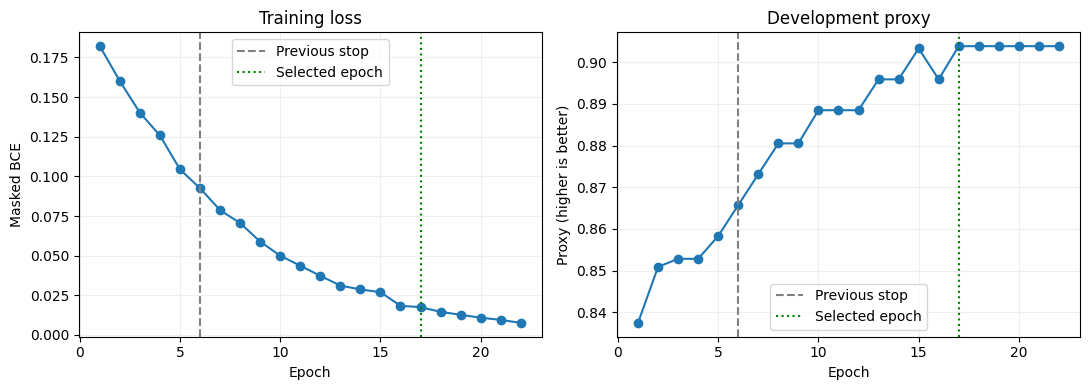

RESULT {'status': 'finished', 'best_epoch': 17, 'epochs_completed': 22, 'best_dev_proxy': 0.9038005610039294, 'submission_status': 'not_submitted'}
DRIVE /content/drive/MyDrive/DACON_236749/runs_v2/epoch_extension_20260913_013624


In [7]:
try:
    (RUN / 'code').mkdir()
    for source in WORK.iterdir():
        if source.is_file():
            shutil.copy2(source,RUN / 'code' / source.name)
    with (RUN / 'install.log').open('w') as log:
        subprocess.run([sys.executable,'-m','pip','install','-q','transformers==4.57.6',
            'scikit-learn==1.8.0','soundfile==0.12.1','safetensors'],
            stdout=log,stderr=subprocess.STDOUT,check=True,timeout=600)
    import torch, importlib.metadata
    assert torch.cuda.is_available()
    (RUN / 'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,
        'gpu':torch.cuda.get_device_name(),'transformers':importlib.metadata.version('transformers')}))
    def sha(path):
        with path.open('rb') as f:
            return hashlib.file_digest(f,'sha256').hexdigest()
    archive_path = WORK / DATA_ARCHIVE['name']
    with archive_path.open('wb') as out:
        for part in DATA_ARCHIVE['parts']:
            source = DRIVE / part['name']
            assert sha(source) == part['sha256']
            with source.open('rb') as incoming:
                shutil.copyfileobj(incoming,out,8*1024**2)
    assert sha(archive_path) == DATA_ARCHIVE['sha256']
    with zipfile.ZipFile(archive_path) as packed:
        packed.extractall(WORK)
    os.chdir(WORK)
    command = [sys.executable,'-u','run_epoch_extension.py','--primary',str(PRIMARY),
        '--data',str(WORK / 'v2_validation'),'--work',str(WORK),'--output',str(RUN),'--deadline',str(DEADLINE)]
    with (RUN / 'experiment.log').open('w') as log:
        process = subprocess.Popen(command,stdout=log,stderr=subprocess.STDOUT)
        while process.poll() is None:
            if time.time() > DEADLINE-60:
                process.terminate()
                process.wait(timeout=30)
                raise TimeoutError('epoch experiment deadline reached')
            time.sleep(15)
            lines = (RUN / 'experiment.log').read_text().splitlines()
            print(lines[-1][:700] if lines else 'Preparing checkpoint...',flush=True)
        if process.returncode:
            raise RuntimeError((RUN / 'experiment.log').read_text()[-10000:])
    report = json.loads((RUN / 'training_report.json').read_text())
    import matplotlib.pyplot as plt
    history = report['reports']
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    axes[0].plot([r['epoch'] for r in history],[r['mean_loss'] for r in history],marker='o')
    axes[0].set(title='Training loss',xlabel='Epoch',ylabel='Masked BCE')
    axes[1].plot([r['epoch'] for r in history],[r['proxy'] for r in history],marker='o')
    axes[1].set(title='Development proxy',xlabel='Epoch',ylabel='Proxy (higher is better)')
    for axis in axes:
        axis.axvline(6,color='gray',linestyle='--',label='Previous stop')
        axis.axvline(report['best_epoch'],color='green',linestyle=':',label='Selected epoch')
        axis.legend()
        axis.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN / 'learning_curve.png',dpi=160)
    plt.show()
    print('RESULT',json.loads((RUN / 'finished.json').read_text()))
    print('DRIVE',RUN)
except Exception:
    (RUN / 'failure.txt').write_text(traceback.format_exc())
    raise
finally:
    (RUN / 'release_requested.json').write_text(json.dumps({'unix':time.time(),'elapsed_seconds':time.time()-SESSION_START}))
    watchdog.cancel()
    runtime.unassign()